# Expected credit loss of one account: term structure, loss given default, exposure and discounting

**Question:** What does one loan cost a bank in expected credit loss over the next 12 months and over its whole life, and why is the lifetime figure several times the 12-month one?

- **Level:** 1, Fundamentals
- **Prerequisites:** topic 01 (getting started), notebooks 01 and 02
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- build the survival, the marginal and the cumulative probability of default from a hazard, and go back from either of the other two to the same hazard;
- write the expected credit loss (ECL) of one account as a sum of discounted marginal losses, and read the 12-month ECL and the lifetime ECL as the same sum over two horizons;
- say why a loan that can also be repaid early has a lower default incidence than its default hazard suggests, and why Contraste's lifetime PD still treats prepayment as censoring;
- state the discount convention (mid-period, at the original effective interest rate) and measure what it changes, against a risk-free rate that IFRS 9 does not allow;
- read how the lifetime-to-12-month ratio of an account grows with the term of its segment.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C06 (mortgage-style lifetime PD, IFRS 9 staging and ECL) as Contraste commits it, at the reporting date 2008-12-31. The loans are the SBA 7(a) small-business loans of the U.S. Small Business Administration, the public twin of the mortgage case (U.S. Government Works, licence class `mirror-allowed`; Freddie Mac's data is not used, the owner's account is missing). The pipeline fitted three lifetime-PD rungs on loans known at the reporting date, projected them under three macroeconomic scenarios and committed the result.

- **Files read:** `data/derived/C06/rd-2008-12.json` for the settings, the horizons and the term structures (`outputs.term_structures`), and `data/derived/C06/models-rd-2008-12.json` for the loss given default of each segment (`fit.lgd.segments`).
- **What the files do not hold:** the balance and the interest rate of one account. The exposure and the rate used below are therefore **stated inputs of this lesson**, labelled as such; the PD curve and the loss given default are the committed ones.

The next cell loads both files and prints the version of the engine that baked them beside the version installed now.

In [2]:
# Load the artifact and the model file of case C06; the notebook sits three folders below the repository root
from riskvalidation.provisions import ecl as ecl_engine, term_structure as tsm

ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C06"
case = json.loads((DERIVED / "rd-2008-12.json").read_text(encoding="utf-8"))
models = json.loads((DERIVED / "models-rd-2008-12.json").read_text(encoding="utf-8"))
out = case["outputs"]
print("engine that baked the artifact:", case["provenance"]["riskvalidation_version"])
print("engine installed now:", md.version("riskvalidation"))
print("reporting date:", out["reporting_date"], "| currency:", out["currency"])
print("months per period:", out["period_months"])

engine that baked the artifact: 1.0.1
engine installed now: 1.0.1
reporting date: 2008-12-31 | currency: USD
months per period: 3


## Method

Contraste's engine states the term structure and the ECL with the identities of IFRS 9 as the survival-analysis literature writes them (Botha and Verster, 2025, equations 6 to 10). For periods $t = 1, \dots, T$ after the reporting date, with $h(t)$ the probability of default in period $t$ given survival to its start (the discrete hazard):

$$S(t) = \prod_{u=1}^{t}\bigl(1 - h(u)\bigr), \qquad q(t) = S(t-1)\,h(t), \qquad F(t) = \sum_{u=1}^{t} q(u) = 1 - S(t), \qquad h(t) = \frac{q(t)}{S(t-1)}$$

Here $S$ is the survival, $q$ the unconditional (marginal) probability of default of the period, $F$ the cumulative PD and $S(0) = 1$. The ECL of an account in a scenario is the sum of the discounted marginal losses (GPPC 2016, section 2.1.1.2; IFRS 9 B5.5.28 and B5.5.43 to B5.5.44):

$$\mathrm{ECL}(T) = \sum_{t=1}^{T} q(t)\; \mathrm{LGD}(t)\; \mathrm{EAD}(t)\; \mathrm{DF}(t), \qquad \mathrm{DF}(t) = (1 + r)^{-\delta(t)/12}$$

with $r$ the original effective interest rate (EIR) and $\delta(t)$ the months from the reporting date to the assumed loss date of period $t$: the midpoint of the period in Contraste's documented convention, the end of the period in the alternative. $T$ is 12 months for the 12-month ECL (Stage 1) and the expected life for the lifetime ECL (Stage 2). The standard fixes the objective, not the formula, and the discount rate is the EIR, never a risk-free rate (IFRS 9 B5.5.44).

Each step below calls the engine (`riskvalidation.provisions`) on the data above and draws or tabulates what it returns. The lesson inputs that the file does not hold (the balance, the interest rate and a prepayment hazard) are stated in capitals where they enter.

### Step 1: the term structure of one segment

The artifact keeps, for each segment and scenario, the hazard by quarter. We take the scenario-weighted curve of the segment of loans with a term over 20 years, the curve a long loan carries, and give its hazard to `from_hazard`, which returns the survival, the marginal and the cumulative PD of the identities above. The cell prints four quarters and draws the structure: bars for the marginal PD with the cumulative PD as a line, and the survival beside it.

month   3 | h 0.001589 | q 0.001589 | F 0.001589 | S 0.998411
month  12 | h 0.001548 | q 0.001541 | F 0.006188 | S 0.993812
month  60 | h 0.001166 | q 0.001134 | F 0.028451 | S 0.971549
month 120 | h 0.000698 | q 0.000667 | F 0.045763 | S 0.954237


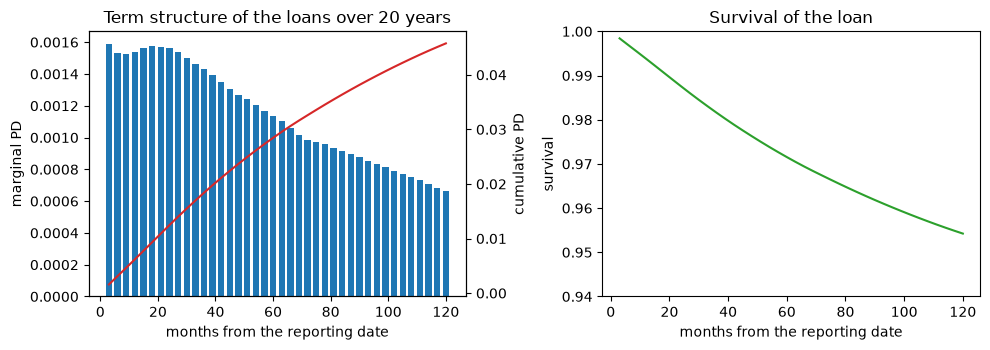

In [3]:
# Rebuild the term structure of one segment from its hazard, print four quarters and draw it
SEGMENT = "term-gt-240"
rows = {(r["scenario_id"], r["segment_id"]): r for r in out["term_structures"]}
curve = rows[("weighted", SEGMENT)]
months = np.array(curve["months"])
ts = tsm.from_hazard(np.array(curve["hazard"]), months)
for k in (0, 3, 19, 39):
    h, q_, f_, s_ = ts.hazard[k], ts.marginal[k], ts.cumulative[k], ts.survival[k]
    print(f"month {int(months[k]):3d} | h {h:.6f} | q {q_:.6f} | F {f_:.6f} | S {s_:.6f}")

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.bar(months, ts.marginal, width=2.2, color="tab:blue", label="marginal PD")
left.set_xlabel("months from the reporting date")
left.set_ylabel("marginal PD")
twin = left.twinx()
twin.plot(months, ts.cumulative, color="tab:red", label="cumulative PD")
twin.set_ylabel("cumulative PD")
left.set_title("Term structure of the loans over 20 years")
right.plot(months, ts.survival, color="tab:green")
right.set_ylim(0.94, 1.0)
right.set_xlabel("months from the reporting date")
right.set_ylabel("survival")
right.set_title("Survival of the loan")
fig.tight_layout()
plt.show()

The marginal PD changes slowly: about 0.16% in the first quarter and falling gently toward 0.07% at the ten-year cap. Because every quarter adds a little, the cumulative PD climbs almost in a straight line to about 4.6% at month 120, and the survival, drawn on the right on a zoomed axis, falls by the same amount. One quarter of this loan is a minor event. Its weight comes from forty such quarters added together, which is what the ECL of step 6 turns into money.

### Step 2: three ways in, one hazard out

A bank rarely starts from a hazard. A scorecard or a vintage table gives the cumulative PD from the reporting date, and a regulatory curve gives the marginal PD. `from_marginal` and `from_cumulative` take those and return the same structure, using $h(t) = q(t)/S(t-1)$. The cell feeds each door the curve of step 1 and prints how far the hazard they return is from the one the first door returned. It then feeds `from_cumulative` a curve that stops rising, which is not a cumulative PD, to see the engine refuse it.

In [4]:
# Recover the hazard through the marginal door and the cumulative door, and see what the engine refuses
from_marginal = tsm.from_marginal(ts.marginal, months)
from_cumulative = tsm.from_cumulative(ts.cumulative, months)
gap_marginal = np.abs(from_marginal.hazard - ts.hazard).max()
gap_cumulative = np.abs(from_cumulative.hazard - ts.hazard).max()
print("largest hazard difference through the marginal PD:", f"{gap_marginal:.1e}")
print("largest hazard difference through the cumulative PD:", f"{gap_cumulative:.1e}")
broken = ts.cumulative.copy()
broken[5] = broken[4]
try:
    tsm.from_cumulative(broken, months)
except ValueError as error:
    print("a cumulative PD that does not rise is refused with", type(error).__name__)

largest hazard difference through the marginal PD: 4.3e-19
largest hazard difference through the cumulative PD: 3.0e-18
a cumulative PD that does not rise is refused with ValueError


Both doors return the hazard of step 1 to the precision of floating point arithmetic, so the three representations are one object seen three ways and the choice of door is a matter of what the bank has at hand. The refusal matters as much: an input that breaks the rules of a cumulative probability becomes an error with a name, and never a wrong ECL that someone has to find later in a report.

### Step 3: the PD over a window

The 12-month ECL needs the PD of the first year, and the staging of notebook 02 needs the PD of the remaining life given survival to the first anniversary. The engine's `forward_pd` returns the conditional PD over $(a, b]$ given survival to $a$, $\mathrm{PD}(a, b) = (S(a) - S(b))/S(a)$. The cell asks for the first year, for months 12 to 120 and for the whole life.

In [5]:
# Ask for the PD over three windows: the first year, the rest of the life and the whole life
first_year = float(tsm.forward_pd(ts, 0, 12))
remaining_life = float(tsm.forward_pd(ts, 12, 120))
whole_life = float(tsm.forward_pd(ts, 0, 120))
print("PD of the first 12 months:", round(first_year, 6))
print("PD of months 12 to 120 given survival to month 12:", round(remaining_life, 6))
print("PD of the whole life:", round(whole_life, 6))

PD of the first 12 months: 0.006188
PD of months 12 to 120 given survival to month 12: 0.039822
PD of the whole life: 0.045763


The first year carries 0.62% of default probability and the remaining nine years carry 3.98%, about six times more, so a loan that is measured over twelve months and a loan that is measured over its life are different quantities even before any loss or discount enters. The three windows compose: surviving the first year and then the rest gives back the PD of the whole life, 4.58%.

### Step 4: prepayment as a competing exit

A loan leaves the book by default or by repayment. If repayment is possible, the loan is no longer exposed in later periods, so the incidence of default is lower than a default hazard that ignores it would give. With cause-specific hazards $h^D$ and $h^P$ the engine's `competing_risks` computes $S^{\mathrm{all}}(t) = \prod_u (1 - h^D(u) - h^P(u))$ and the default incidence $q^D(t) = S^{\mathrm{all}}(t-1)\,h^D(t)$ (Botha and Verster, 2025; IFRS 9 B5.5.51 asks for the effect of expected prepayments). Contraste's C06 carries no prepayment hazard: the committed finding `F-PREPAYMENT` treats prepayment as censoring. To show the effect the cell adds a **stated, illustrative** hazard of 1% a quarter, which is not a Contraste estimate.

cumulative default, default hazard only: 0.045763
cumulative default incidence with prepayment: 0.039038
probability of leaving the book by either exit: 0.361945


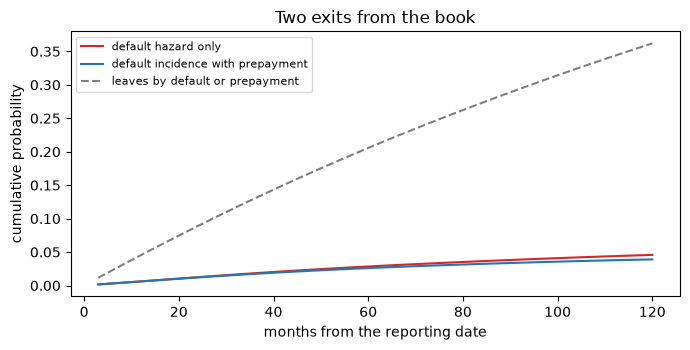

In [6]:
# Add a stated prepayment hazard to the default hazard and compare the three cumulative curves
PREPAY_HAZARD = 0.01  # illustrative input of the lesson, per quarter
competing = tsm.competing_risks(ts.hazard, np.full(ts.hazard.shape, PREPAY_HAZARD), months)
leaves = 1.0 - competing.survival_all
print("cumulative default, default hazard only:", round(float(ts.cumulative[-1]), 6))
with_prepayment = competing.cumulative_default
print("cumulative default incidence with prepayment:", round(float(with_prepayment[-1]), 6))
print("probability of leaving the book by either exit:", round(float(leaves[-1]), 6))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(months, ts.cumulative, color="tab:red", label="default hazard only")
ax.plot(months, with_prepayment, color="tab:blue", label="default incidence with prepayment")
ax.plot(months, leaves, color="tab:grey", linestyle="--", label="leaves by default or prepayment")
ax.set_xlabel("months from the reporting date")
ax.set_ylabel("cumulative probability")
ax.set_title("Two exits from the book")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The red and the blue curves separate slowly: with prepayment the loans that would have defaulted late are often gone before they can, so the cumulative default incidence at month 120 is 3.90% against 4.58%. The dashed curve is the lesson of the step. Over a third of the book leaves by one of the two exits, so the probability of leaving is not the probability of defaulting. C06 chooses censoring, which sits on the cautious side of this picture.

### Step 5: the discount factor

Each loss is brought back to the reporting date at the original effective interest rate (EIR). `discount_factors` returns $(1 + r)^{-\delta/12}$ for each account and period. With the mid-period convention a loss of the first quarter is discounted 1.5 months, not 3, because the default is assumed to fall in the middle of the quarter. The rate is a **stated input** of 8% a year, since the artifact holds no per-account rate. The cell prints the first four factors under both conventions.

In [7]:
# Discount factors of one account under the two conventions
EIR = np.array([0.08])  # illustrative input of the lesson, per year
df_mid = ecl_engine.discount_factors(EIR, months, "mid-period")[0]
df_end = ecl_engine.discount_factors(EIR, months, "end-of-period")[0]
print("mid-period, first four periods:", np.round(df_mid[:4], 6))
print("end-of-period, first four periods:", np.round(df_end[:4], 6))

mid-period, first four periods: [0.990426 0.971552 0.953038 0.934876]
end-of-period, first four periods: [0.980944 0.96225  0.943913 0.925926]


The mid-period factors are slightly higher than the end-of-period ones, 0.9904 against 0.9809 for the first quarter, because the loss is assumed a month and a half closer. The difference is small per quarter and is repeated forty times, so step 7 measures what it does to the lifetime ECL.

### Step 6: the ECL of one account, 12 months and lifetime

`ecl_scenario` evaluates $\sum_{t \le T} q\,\mathrm{LGD}\,\mathrm{EAD}\,\mathrm{DF}$ for a batch of accounts. We give it one account: the marginal PD of step 1, the loss given default the pipeline estimated for this segment (`fit.lgd.segments`, a charge-off severity proxy), an exposure of 100,000 USD (a stated lesson input, constant here; the pipeline amortises it, see `F-EAD-MODEL`), the stated rate, and a horizon. A horizon of 12 months gives the Stage 1 figure and the whole life gives the Stage 2 figure. Asking for every horizon in turn draws how the ECL builds up.

loss given default of the segment: 0.532313
12-month ECL, USD: 317.09 | lifetime ECL, USD: 1799.23
lifetime over 12-month ECL: 5.674


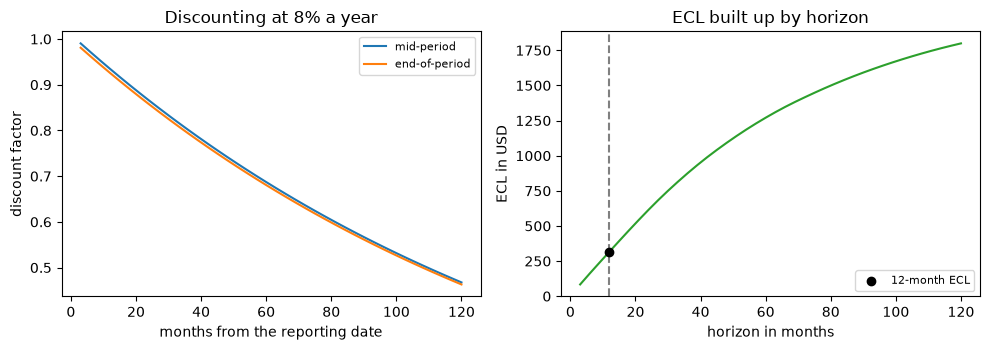

In [8]:
# Compute the 12-month and the lifetime ECL of one account and its build-up by horizon
lgd_by_segment = {s["segment_id"]: s["lgd"] for s in models["fit"]["lgd"]["segments"]}
lgd = lgd_by_segment[SEGMENT]
EAD = 100_000.0  # illustrative input of the lesson, constant over the life
q = ts.marginal[None, :]
ecl_12 = float(ecl_engine.ecl_scenario(q, lgd, EAD, EIR, months, 12, "mid-period")[0])
ecl_life = float(ecl_engine.ecl_scenario(q, lgd, EAD, EIR, months, int(months[-1]), "mid-period")[0])
build_up = [float(ecl_engine.ecl_scenario(q, lgd, EAD, EIR, months, int(h), "mid-period")[0]) for h in months]
print("loss given default of the segment:", round(lgd, 6))
print("12-month ECL, USD:", round(ecl_12, 2), "| lifetime ECL, USD:", round(ecl_life, 2))
print("lifetime over 12-month ECL:", round(ecl_life / ecl_12, 3))

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.plot(months, df_mid, color="tab:blue", label="mid-period")
left.plot(months, df_end, color="tab:orange", label="end-of-period")
left.set_xlabel("months from the reporting date")
left.set_ylabel("discount factor")
left.set_title("Discounting at 8% a year")
left.legend(fontsize=8)
right.plot(months, build_up, color="tab:green")
right.axvline(12, color="grey", linestyle="--")
right.scatter([12], [ecl_12], color="black", zorder=3, label="12-month ECL")
right.set_xlabel("horizon in months")
right.set_ylabel("ECL in USD")
right.set_title("ECL built up by horizon")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

For an account of 100,000 USD the 12-month ECL is 317.09 USD, 0.32% of the exposure, and the lifetime ECL is 1,799.23 USD, 1.80%. The right panel shows why they differ: the build-up curve is a running sum of small, nearly equal contributions, the 12-month figure is that curve read at month 12, and the lifetime figure is its end. The discount factors of the left panel bend the curve down a little at late horizons without changing its shape.

### Step 7: what the convention and the rate change

Two choices move the ECL without moving the credit risk: the discount convention and the rate. IFRS 9 B5.5.44 fixes the rate at the EIR. A risk-free rate is lower than the EIR, discounts less and gives a larger ECL, which is not the standard's measure. The cell recomputes the lifetime ECL under the end-of-period convention and with a risk-free rate of 2% a year, a stated lesson input, and prints each change against the setting of step 6.

In [9]:
# Recompute the lifetime ECL with the other convention and with a risk-free rate
RISK_FREE = np.array([0.02])  # illustrative input of the lesson, per year
life = int(months[-1])
end_of_period = float(ecl_engine.ecl_scenario(q, lgd, EAD, EIR, months, life, "end-of-period")[0])
risk_free = float(ecl_engine.ecl_scenario(q, lgd, EAD, RISK_FREE, months, life, "mid-period")[0])
print("lifetime ECL, mid-period at the EIR (the setting), USD:", round(ecl_life, 2))
print("lifetime ECL, end-of-period at the EIR, USD:", round(end_of_period, 2))
print("change:", round(end_of_period / ecl_life - 1.0, 5))
print("lifetime ECL, mid-period at a risk-free rate, USD:", round(risk_free, 2))
print("change:", round(risk_free / ecl_life - 1.0, 5))

lifetime ECL, mid-period at the EIR (the setting), USD: 1799.23
lifetime ECL, end-of-period at the EIR, USD: 1782.0
change: -0.00957
lifetime ECL, mid-period at a risk-free rate, USD: 2243.83
change: 0.24711


The convention is a second-order choice: moving the loss to the end of the quarter lowers the lifetime ECL by 0.96%. The rate is a first-order one: a risk-free rate of 2% raises it by 24.7%. A figure that moves by a quarter because of a discount rate that the standard does not allow would not be a measure of credit risk, which is why the discount rate is part of the documented setting and not a free parameter.

### Step 8: the four segments, and what the horizon does

The same calculation on the four segments of the committed model shows how much of the lifetime loss falls in the first year. A short loan has most of its loss inside 12 months. A long loan has a small first-year ECL and a lifetime ECL several times larger. That ratio is the jump a loan makes when it moves from Stage 1 to Stage 2, the cliff of notebook 02. Each segment uses its own committed curve and loss given default, with the exposure and the rate of this lesson.

up to 5 years    | loss given default 1.0000 | ratio  2.21
                 | 12 months   7932.85 | lifetime  17498.45
5 to 10 years    | loss given default 1.0000 | ratio  3.79
                 | 12 months   3153.63 | lifetime  11964.31
10 to 20 years   | loss given default 0.6737 | ratio  5.05
                 | 12 months    863.06 | lifetime   4361.50
over 20 years    | loss given default 0.5323 | ratio  5.67
                 | 12 months    317.09 | lifetime   1799.23


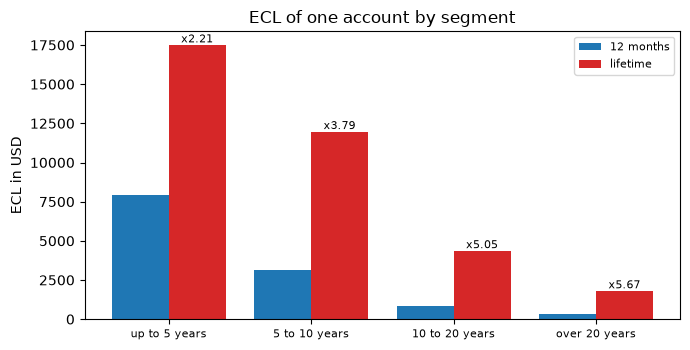

In [10]:
# Compute the 12-month and the lifetime ECL of an account in each of the four segments
labels = {
    "term-le-60": "up to 5 years",
    "term-61-120": "5 to 10 years",
    "term-121-240": "10 to 20 years",
    "term-gt-240": "over 20 years",
}
by_segment = {}
for segment in labels:
    c = rows[("weighted", segment)]
    m = np.array(c["months"])
    marginal = tsm.from_hazard(np.array(c["hazard"]), m).marginal[None, :]
    lgd_s = lgd_by_segment[segment]
    e12 = float(ecl_engine.ecl_scenario(marginal, lgd_s, EAD, EIR, m, 12)[0])
    elife = float(ecl_engine.ecl_scenario(marginal, lgd_s, EAD, EIR, m, int(m[-1]))[0])
    by_segment[segment] = (e12, elife)
    print(f"{labels[segment]:16s} | loss given default {lgd_s:.4f} | ratio {elife / e12:5.2f}")
    print(f"{'':16s} | 12 months {e12:9.2f} | lifetime {elife:9.2f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(labels))
ax.bar(x - 0.2, [v[0] for v in by_segment.values()], width=0.4, color="tab:blue", label="12 months")
ax.bar(x + 0.2, [v[1] for v in by_segment.values()], width=0.4, color="tab:red", label="lifetime")
for k, (e12_k, elife_k) in enumerate(by_segment.values()):
    ax.text(k + 0.2, elife_k, f"x{elife_k / e12_k:.2f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(list(labels.values()), fontsize=8)
ax.set_ylabel("ECL in USD")
ax.set_title("ECL of one account by segment")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The two shortest segments carry a loss given default of 1.0, the pipeline's charge-off severity proxy, which has an upward bias (finding `F-LGD-PROXY`), so their absolute figures are the cautious ones; the comparison that matters is the ratio. It grows with the term, from 2.21 for loans up to five years to 5.67 above twenty, because a long loan keeps most of its exposure and most of its default probability beyond the first anniversary.

## Results

**Answer:** One loan of the segment over 20 years costs 317.09 USD of expected credit loss over 12 months and 1,799.23 USD over its whole life, 5.67 times more, because the default probability of the first 12 months is 0.0062 while that of the remaining nine years is 0.0398, so most of the lifetime loss falls after the first anniversary.

- **One hazard, three doors.** The survival, the marginal and the cumulative PD of the long-loan segment are one object: entering by the marginal or the cumulative PD returns the hazard of step 1 to within 1e-17, and a cumulative PD that stops rising is refused with a `ValueError` before it can become a wrong ECL.
- **The first year is a small part of a long loan.** The PD of the first 12 months is 0.0062, the PD of months 12 to 120 given survival to month 12 is 0.0398 and the whole life carries 0.0458. This is why a loan that moves from Stage 1 to Stage 2 changes its measurement so much.
- **Prepayment matters and Contraste's lifetime PD does not carry it.** With an illustrative prepayment hazard of 1% a quarter the cumulative default incidence at month 120 falls from 0.0458 to 0.0390 and 36% of the loans leave the book by one of the two exits. C06 treats prepayment as censoring (finding `F-PREPAYMENT`), so on this point its lifetime ECL is on the cautious side.
- **The ECL is a sum you can read.** For the lesson account the 12-month ECL is 317.09 USD (0.32% of the exposure) and the lifetime ECL is 1,799.23 USD (1.80%).
- **Convention and rate are not equal choices.** The end-of-period convention lowers the lifetime ECL by 0.96%; a risk-free rate of 2% raises it by 24.7%, which is why IFRS 9 fixes the rate at the EIR.
- **The horizon effect depends on the term.** The ratio of the lifetime to the 12-month ECL is 2.21 for loans up to 5 years, 3.79 for 5 to 10 years, 5.05 for 10 to 20 years and 5.67 above 20 years.

What this notebook does not show: the exposure and the rate are inputs of the lesson, not data of the file, and the pipeline amortises the balance (finding `F-EAD-MODEL`) where the lesson keeps it constant. The staging that decides which of the two ECLs a loan carries is notebook 02; the weighting of the three scenarios is notebook 03.

## Summary

- The survival, the marginal and the cumulative PD are one object seen three ways; the engine builds it from a hazard, a marginal PD or a cumulative PD and refuses inputs that are not valid.
- The ECL of an account is the sum over periods of the marginal PD, the loss given default, the exposure and the discount factor. The 12-month ECL and the lifetime ECL are the same sum cut at two horizons.
- Discounting is at the original EIR, mid-period by Contraste's documented setting; the alternative convention changes the figure by a few tenths of a percent and a risk-free rate changes it by a quarter, without changing the risk.
- A competing exit such as prepayment lowers the default incidence and is not the complement of the survival; C06 records its choice, censoring, as a finding.

**What to try next.** Change `PREPAY_HAZARD` to 0 and then to 0.03 and watch the default incidence; change `SEGMENT` to `term-le-60`. Then continue with notebook 02, which decides which of the two ECLs each loan carries.

## References

- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- Botha, A. and Verster, T. (2025), Approaches for modelling the term-structure of default risk under IFRS 9: a tutorial using discrete-time survival analysis, equations 6 to 10. https://arxiv.org/abs/2507.15441
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 June 2016, sections 2.1.1, 2.7.2 and 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf